<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [National Weather Service](https://github.com/Query-farm/vgi-nws)

Explore US weather alerts, observations, forecast grids, bulletins, and river conditions.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-nws/blob/main/notebooks/03_an_update_is_not_an_extra_hazard.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-nws/blob/main/notebooks/README.md)


## 03 · An update is not an extra hazard

How many messages remain after accounting for explicit update references, and where
should you retrieve their supporting text? We use a synthetic state alert list, a
point query narrowed to one event, and complete message records. Then distinguish
alert messages, bulletin indexes, full bulletins and office asset links.

The example illustrates provenance and message identity. It does not implement a full
CAP lifecycle engine or produce a current hazard assessment. Every message has synthetic
content and `status = Test`.

### Choose whether to retain referenced predecessors

`KEEP_REFERENCED = False` excludes a point-query message when another returned message
explicitly references its identifier. Set **True** for the experiment to retain both
versions. This is a local display rule over this complete two-message fixture, not a
general rule that references always invalidate alerts. Real cancellations, partially
available chains and status/scope changes require further interpretation.

In [1]:
KEEP_REFERENCED = False  # Experiment: True

### Run independently

Read the saved results on GitHub or choose **Open in Colab** and Run All. The brief
base install preserves compatible preloaded plotting and kernel libraries. Local
publication uses the optional `[runner]` extra. Initial packages, verified companions,
VGI and native worker download need internet. No worker checkout, Bun or source build
is required. Hosted Colab is not tested; a fresh preloaded Python 3.12 notebook-only
execution checks the common setup path. [Detailed setup and provenance](README.md).

In [2]:
import importlib.metadata as packages

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.40":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.40"
from vgi_notebooks import check_runtime

check_runtime()
if packages.version("vgi-example-notebooks") != "0.3.40":
    raise RuntimeError("Install shared tools 0.3.40, restart, and Run All.")

In [3]:
import json
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from vgi_notebooks import prepare
from vgi_notebooks.presentation import finish, prose, theme
from vgi_notebooks.session import connect

prepare("nws")
from scenario_source import ScenarioSource

%matplotlib inline
theme()
session = connect(globals())
con = session.connection
assert con.execute("SELECT name FROM duckdb_secrets()").fetchall() == []
assert con.execute("SELECT current_setting('TimeZone')").fetchone()[0] == "UTC"
source = ScenarioSource()
Path("artifacts").mkdir(exist_ok=True)
PROVENANCE = "Source: synthetic NOAA-shaped teaching inputs · 2 January 2026 UTC · not live conditions"

if type(KEEP_REFERENCED) is not bool:
    raise ValueError("KEEP_REFERENCED must be a boolean")

### Source boundary

Every value in this story is **synthetic**. The real released NWS worker parses
NOAA-shaped documents served only on loopback; all ten upstream roots are scoped to
that local service and unknown requests fail. No real alert, gauge condition or forecast
is represented. Canonical `source_url` values are emitted by the worker even in this
mode: they describe product routes, not proof of a live request. `fetched_at` is the
local read time. The fixture's fixed scenario time is **2026-01-02 12:00 UTC**.

Shared setup uses an empty temporary SQL-secret directory, disables persistence and
JupySQL default connection autoload, and fixes the connection timezone to UTC. No key,
saved secret or account write is involved. Cleanup closes the connection/service and
restores the temporary process environment.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'nws' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-nws@v0.4.0');

,Success


### Resolve messages and retain their references

`alert_types` supplies accepted event labels. The state query includes all synthetic
recent event types; the point query explicitly filters **Freeze Warning**, so their
different counts cannot be attributed to geography alone. Materialize both, then retrieve
full details by identifier. NULL alert geometry does not mean an empty affected area:
these point messages carry forecast-zone links instead.

The fixture contains an Alert followed by an Update referencing that Alert. Keep the
original IDs, reference JSON, sent time, applicability window and status visible before
applying the display choice.

In [5]:
%%sql
CREATE TABLE event_types AS SELECT * FROM nws.main.alert_types();
CREATE TABLE state_messages AS SELECT * FROM nws.main.alerts(area:='VA',active:=false);
CREATE TABLE point_messages AS SELECT * FROM nws.main.alerts_at(
 38.0293,-78.4767,event:='Freeze Warning',active:=false);
CREATE TABLE details AS SELECT d.* FROM point_messages a,LATERAL nws.main.alert(a.id) d;
CREATE TABLE message_references AS
SELECT d.id AS referencing_id,json_extract_string(r.value,'$.identifier') AS referenced_id
FROM details d,LATERAL json_each(d.references_json) r;
CREATE TABLE message_selection AS
SELECT d.*,EXISTS(SELECT 1 FROM message_references r WHERE r.referenced_id=d.id) AS is_referenced,
 {{KEEP_REFERENCED}} OR NOT EXISTS(SELECT 1 FROM message_references r WHERE r.referenced_id=d.id) AS selected
FROM details d;
SELECT event,count(*) AS state_message_rows FROM state_messages GROUP BY event ORDER BY event;
SELECT t.event,count(m.id) AS point_query_rows FROM event_types t LEFT JOIN point_messages m USING(event)
GROUP BY t.event ORDER BY t.event;
SELECT id,message_type,status,sent,onset,expires,geometry_json,affected_zones_json,is_referenced,selected
FROM message_selection ORDER BY sent;
SELECT * FROM message_references ORDER BY referencing_id;

,referencing_id,referenced_id
0,urn:oid:synthetic-2,urn:oid:synthetic-1


In [6]:
%%sql messages <<
SELECT id,message_type,status,sent,onset,expires,is_referenced,selected FROM message_selection ORDER BY sent;

In [7]:
display(messages)
selected_ids = messages.loc[messages.selected, "id"].tolist()
prose(
    f"The point/event query contains **{len(messages)} message rows** and **{int(messages.is_referenced.sum())} explicitly referenced predecessor**. The display keeps **{len(selected_ids)} message(s)**. This is a count of versions, not independent hazards or affected people. Both full records remain stored; missing polygons do not erase their zone links."
)

,id,message_type,status,sent,onset,expires,is_referenced,selected
0,urn:oid:synthetic-1,Alert,Test,2026-01-02 10:00:00+00:00,2026-01-02 13:00:00+00:00,2026-01-02 18:00:00+00:00,True,False
1,urn:oid:synthetic-2,Update,Test,2026-01-02 11:00:00+00:00,2026-01-02 13:00:00+00:00,2026-01-02 18:00:00+00:00,False,True


The point/event query contains **2 message rows** and **1 explicitly referenced predecessor**. The display keeps **1 message(s)**. This is a count of versions, not independent hazards or affected people. Both full records remain stored; missing polygons do not erase their zone links.

### An index entry is a route to text, not the text itself

Discover product codes and the locations that issue a chosen type. A missing location
label does not invalidate its identifier. The **AFD** index returns two identifiers
without full text; `product(id)` retrieves each full bulletin. `latest_product` independently
returns the newest one in this fixture. Index ordering is not used as a recency rule.

Office `briefing` and `weather_stories` return metadata and links. Neither call downloads
a PDF/image or turns the linked asset into an alert. Their applicability times and update
times are distinct from alert issuance and bulletin issuance. All content here is synthetic.

In [8]:
%%sql
CREATE TABLE product_types AS SELECT * FROM nws.main.product_types();
CREATE TABLE locations AS SELECT * FROM nws.main.product_locations('AFD');
CREATE TABLE bulletin_index AS SELECT * FROM nws.main.products('AFD','LWX');
CREATE TABLE bulletin_text AS SELECT t.* FROM bulletin_index i,LATERAL nws.main.product(i.id) t;
CREATE TABLE latest_bulletin AS SELECT * FROM nws.main.latest_product('AFD','LWX');
CREATE TABLE briefing AS SELECT * FROM nws.main.briefing('LWX');
CREATE TABLE stories AS SELECT * FROM nws.main.weather_stories('LWX');
SELECT t.code,t.name,l.office_id,l.name AS location_label FROM product_types t CROSS JOIN locations l
WHERE t.code='AFD' ORDER BY l.office_id;
SELECT i.id,i.issued_at,i.product_text IS NULL AS index_omits_text,length(t.product_text) AS full_text_characters,
 i.id IN (SELECT id FROM latest_bulletin) AS returned_as_latest FROM bulletin_index i JOIN bulletin_text t USING(id)
ORDER BY i.issued_at;
SELECT id,product_text FROM latest_bulletin;
SELECT 'briefing' AS kind,title,start_time,end_time,updated_at,download_url FROM briefing
UNION ALL SELECT 'story',title,start_time,end_time,updated_at,download_url FROM stories;

,kind,title,start_time,end_time,updated_at,download_url
0,briefing,Synthetic office briefing,2026-01-02 10:00:00+00:00,2026-01-02 18:00:00+00:00,2026-01-02 11:00:00+00:00,https://example.invalid/synthetic-briefing.pdf
1,story,Synthetic office story,2026-01-02 10:00:00+00:00,2026-01-02 18:00:00+00:00,2026-01-02 11:00:00+00:00,https://example.invalid/synthetic-story.png


In [9]:
%%sql roles <<
SELECT 'Bulletin index' AS source,count(*) AS rows,count(product_text) AS text_rows,0::BIGINT AS asset_links FROM bulletin_index
UNION ALL SELECT 'Full bulletins',count(*),count(product_text),0 FROM bulletin_text
UNION ALL SELECT 'Latest bulletin',count(*),count(product_text),0 FROM latest_bulletin
UNION ALL SELECT 'Briefing metadata',count(*),0,count(download_url) FROM briefing
UNION ALL SELECT 'Story metadata',count(*),0,count(download_url) FROM stories;

In [10]:
display(roles)
prose(
    "The bulletin index has **two rows and no full text**, while both full records contain text. The latest lookup matches the newest indexed issue. Briefing and story calls each return one link, with **no binary asset download**. These are distinct information products; adding their row counts would not measure weather severity."
)

,source,rows,text_rows,asset_links
0,Bulletin index,2,0,0
1,Full bulletins,2,2,0
2,Latest bulletin,1,1,0
3,Briefing metadata,1,0,1
4,Story metadata,1,0,1


The bulletin index has **two rows and no full text**, while both full records contain text. The latest lookup matches the newest indexed issue. Briefing and story calls each return one link, with **no binary asset download**. These are distinct information products; adding their row counts would not measure weather severity.

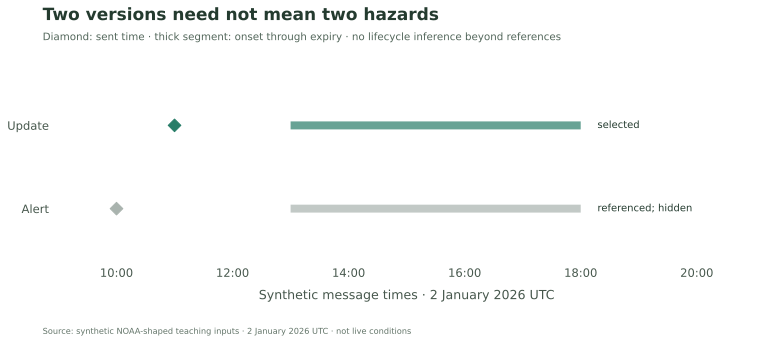

In [11]:
fig, ax = plt.subplots(figsize=(11, 5))
for i, r in enumerate(messages.itertuples()):
    color = "#287D68" if r.selected else "#A9B3AE"
    ax.hlines(i, mdates.date2num(r.onset), mdates.date2num(r.expires), linewidth=8, color=color, alpha=0.7)
    ax.scatter(mdates.date2num(r.sent), i, marker="D", color=color, s=80, zorder=3)
    ax.text(
        mdates.date2num(r.expires) + 0.012,
        i,
        "selected" if r.selected else "referenced; hidden",
        va="center",
        fontsize=10,
    )
ax.set(
    yticks=range(len(messages)),
    yticklabels=messages.message_type,
    xlabel="Synthetic message times · 2 January 2026 UTC",
    ylim=(-0.6, 1.6),
)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz="UTC"))
ax.set_xlim(pd.Timestamp("2026-01-02T09:00:00Z"), pd.Timestamp("2026-01-02T21:00:00Z"))
finish(
    fig,
    "Two versions need not mean two hazards",
    "Diamond: sent time · thick segment: onset through expiry · no lifecycle inference beyond references",
    PROVENANCE,
    name=f"message-versions-{KEEP_REFERENCED}",
)

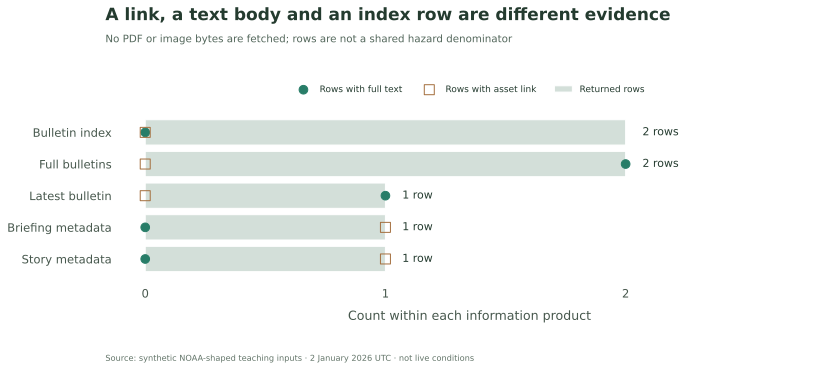

In [12]:
fig, ax = plt.subplots(figsize=(11, 5.4))
y = np.arange(len(roles))
ax.barh(y, roles.rows, color="#D3DFD9", label="Returned rows")
ax.scatter(roles.text_rows, y, color="#287D68", s=75, label="Rows with full text", zorder=3)
ax.scatter(
    roles.asset_links,
    y,
    marker="s",
    facecolors="none",
    edgecolors="#A46F3E",
    s=100,
    label="Rows with asset link",
    zorder=4,
)
for i, r in enumerate(roles.itertuples()):
    ax.text(r.rows + 0.07, i, f"{r.rows} {'row' if r.rows == 1 else 'rows'}", va="center")
ax.set(
    yticks=y,
    yticklabels=roles.source,
    xlabel="Count within each information product",
    xlim=(-0.1, 2.8),
    xticks=[0, 1, 2],
)
ax.invert_yaxis()
fig.legend(loc="upper center", bbox_to_anchor=(0.53, 0.79), ncols=3, fontsize=9)
finish(
    fig,
    "A link, a text body and an index row are different evidence",
    "No PDF or image bytes are fetched; rows are not a shared hazard denominator",
    PROVENANCE,
    name="message-product-roles",
)

### Check the bounded example, not a general warning system

Verify identifiers, explicit references and the index-to-detail links. Retain missing
geometry and location labels. A source timestamp or URL alone is not proof of current
live conditions; this entire fixture remains local and synthetic.

In [13]:
%%sql checks <<
SELECT 'three state message IDs' AS check_name,count(*)=3 AND count(DISTINCT id)=3 AS passed FROM state_messages
UNION ALL SELECT 'point event filter explicit',count(*)=2 AND bool_and(event='Freeze Warning') FROM point_messages
UNION ALL SELECT 'full messages reconcile with point index',NOT EXISTS((SELECT id FROM details EXCEPT SELECT id FROM point_messages) UNION ALL (SELECT id FROM point_messages EXCEPT SELECT id FROM details))
UNION ALL SELECT 'test status retained',bool_and(status='Test') FROM details
UNION ALL SELECT 'zone links despite absent polygons',count(geometry_json)=0 AND bool_and(json_array_length(affected_zones_json)=1) FROM details
UNION ALL SELECT 'one explicit predecessor',count(*)=1 AND min(referenced_id)='urn:oid:synthetic-1' FROM message_references
UNION ALL SELECT 'selection only changes reference policy',count(*) FILTER(WHERE selected)=CASE WHEN {{KEEP_REFERENCED}} THEN 2 ELSE 1 END FROM message_selection
UNION ALL SELECT 'missing location label retained',count(*)=2 AND count(name)=1 FROM locations
UNION ALL SELECT 'index omits text',count(*)=2 AND count(product_text)=0 FROM bulletin_index
UNION ALL SELECT 'details supply both texts',count(*)=2 AND count(product_text)=2 FROM bulletin_text
UNION ALL SELECT 'latest matches greatest issuance',(SELECT id FROM latest_bulletin)=(SELECT id FROM bulletin_index ORDER BY issued_at DESC LIMIT 1)
UNION ALL SELECT 'asset metadata independent',(SELECT count(*)=1 FROM briefing) AND (SELECT count(*)=1 FROM stories);

In [14]:
assert len(checks) == 12 and checks.passed.all()
requests = source.audit()
assert not any("download" in r["path"] or r["path"].endswith((".png", ".pdf")) for r in requests)
display(checks)
prose(
    f"All **{len(checks)} SQL checks** pass. **{len(requests)} local requests** supplied metadata/text; no linked binary asset was downloaded."
)
Path("artifacts/message-audit.json").write_text(
    json.dumps(
        {
            "parameter": KEEP_REFERENCED,
            "messages": messages.to_dict("records"),
            "roles": roles.to_dict("records"),
            "checks": checks.to_dict("records"),
            "requests": requests,
        },
        indent=2,
        default=str,
    )
    + "\n"
)

,check_name,passed
0,three state message IDs,True
1,point event filter explicit,True
2,full messages reconcile with point index,True
3,test status retained,True
4,zone links despite absent polygons,True
5,one explicit predecessor,True
6,selection only changes reference policy,True
7,missing location label retained,True
8,index omits text,True
9,details supply both texts,True


All **12 SQL checks** pass. **13 local requests** supplied metadata/text; no linked binary asset was downloaded.

4142

### Experiment: retain both message versions

Set only **KEEP_REFERENCED to True**. The selected display grows from one to two message
versions, with every identifier, timestamp, reference, bulletin and asset link unchanged.
The source-role chart must be identical. This reveals what the local predecessor rule
removed; it does not create an extra meteorological event. Restore False afterward.

In [15]:
assert con.execute("SELECT name FROM duckdb_secrets()").fetchall() == []
session.close()
source.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-nws](https://github.com/Query-farm/vgi-nws)